In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

variables = pd.read_parquet("data/clean/variables_modelo.parquet")
X = variables.drop(columns=["id_cliente", "sexo", "impago_mes_siguiente"])
y = variables["impago_mes_siguiente"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

modelo_lgb = joblib.load("data/clean/modelo_lightgbm.joblib")

prueba = pd.DataFrame({
    "pd": modelo_lgb.predict_proba(X_test)[:, 1],
    "impago": y_test,
    "sexo": variables.loc[X_test.index, "sexo"],
})
prueba.head()

,pd,impago,sexo
1496,0.177973,0.0,hombre
21394,0.612719,1.0,mujer
15029,0.119776,0.0,hombre
12560,0.161677,0.0,hombre
16096,0.056433,0.0,mujer


,clientes,pd_media,impago_real
decil,,,
1,898,0.049,0.043
2,897,0.068,0.068
3,897,0.084,0.103
4,897,0.104,0.119
5,898,0.129,0.143
6,897,0.156,0.165
7,897,0.190,0.194
8,897,0.262,0.282
9,897,0.427,0.423


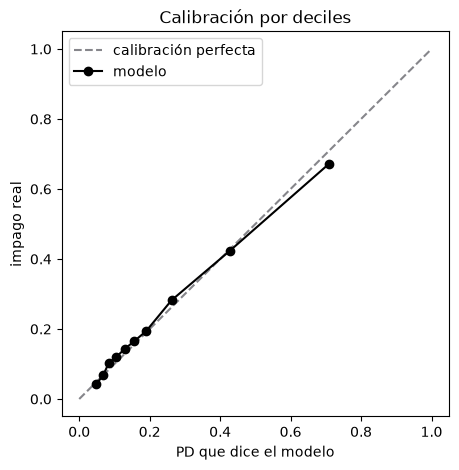

In [2]:
prueba["decil"] = pd.qcut(prueba["pd"], q=10, labels=False) + 1
calibracion = prueba.groupby("decil").agg(
    clientes=("pd", "size"),
    pd_media=("pd", "mean"),
    impago_real=("impago", "mean"),
).round(3)
display(calibracion)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="#86868B", label="calibración perfecta")
ax.plot(calibracion["pd_media"], calibracion["impago_real"], marker="o", color="black", label="modelo")
ax.set(xlabel="PD que dice el modelo", ylabel="impago real", title="Calibración por deciles")
ax.legend()
plt.show()

In [3]:
cortes = [0, 0.10, 0.20, 0.35, 0.55, 1]
prueba["tramo"] = pd.cut(prueba["pd"], bins=cortes, labels=["A", "B", "C", "D", "E"])
tramos = prueba.groupby("tramo", observed=True).agg(
    clientes=("pd", "size"),
    pd_media=("pd", "mean"),
    impago_real=("impago", "mean"),
)
tramos["% de clientes"] = tramos["clientes"] / tramos["clientes"].sum()
display(tramos.round(3))

,clientes,pd_media,impago_real,% de clientes
tramo,,,,
A,2971,0.070,0.076,0.331
B,3089,0.145,0.153,0.344
C,1315,0.264,0.280,0.147
D,613,0.436,0.444,0.068
E,985,0.695,0.655,0.110


,corte,% denegados,% de impagos evitados,coste
0,0.05,0.950,0.993,6619
1,0.10,0.669,0.886,5374
2,0.15,0.473,0.767,5033
3,0.20,0.325,0.648,5123
4,0.25,0.259,0.577,5371
5,0.30,0.217,0.522,5655
6,0.35,0.178,0.462,6016
7,0.40,0.154,0.420,6301
8,0.45,0.136,0.385,6564
9,0.50,0.123,0.355,6790


Corte con menor coste: PD ≥ 15% → se deniega al 47% y se evita el 77% de los impagos


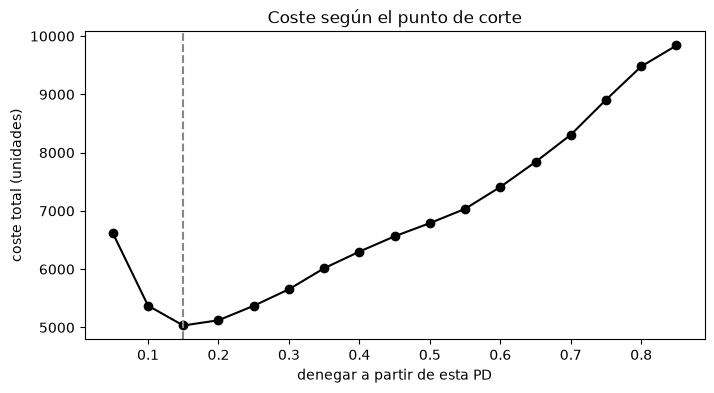

In [4]:
COSTE_IMPAGO = 5
COSTE_CLIENTE_PERDIDO = 1

filas = []
for corte in np.arange(0.05, 0.90, 0.05):
    deniega = prueba["pd"] >= corte
    impagos_aprobados = ((~deniega) & (prueba["impago"] == 1)).sum()
    buenos_denegados = (deniega & (prueba["impago"] == 0)).sum()
    filas.append({
        "corte": round(corte, 2),
        "% denegados": deniega.mean(),
        "% de impagos evitados": (deniega & (prueba["impago"] == 1)).sum() / prueba["impago"].sum(),
        "coste": impagos_aprobados * COSTE_IMPAGO + buenos_denegados * COSTE_CLIENTE_PERDIDO,
    })

costes = pd.DataFrame(filas)
mejor = costes.loc[costes["coste"].idxmin()]
display(costes.round(3))
print(f"Corte con menor coste: PD ≥ {mejor['corte']:.0%} → se deniega al {mejor['% denegados']:.0%} "
      f"y se evita el {mejor['% de impagos evitados']:.0%} de los impagos")

ax = costes.plot(x="corte", y="coste", marker="o", color="black", legend=False, figsize=(8, 4))
ax.axvline(mejor["corte"], linestyle="--", color="#86868B")
ax.set(xlabel="denegar a partir de esta PD", ylabel="coste total (unidades)", title="Coste según el punto de corte")
plt.show()

In [5]:
CORTE = mejor["corte"]

for sexo, grupo in prueba.groupby("sexo"):
    print(
        f"{sexo:>7}: {len(grupo):>5} clientes · "
        f"impago real {grupo['impago'].mean():.1%} · "
        f"PD media {grupo['pd'].mean():.1%} · "
        f"Gini {2 * roc_auc_score(grupo['impago'], grupo['pd']) - 1:.3f} · "
        f"denegados {(grupo['pd'] >= CORTE).mean():.1%}"
    )

 hombre:  3479 clientes · impago real 23.8% · PD media 23.3% · Gini 0.532 · denegados 51.0%
  mujer:  5494 clientes · impago real 21.1% · PD media 20.8% · Gini 0.554 · denegados 45.0%


In [6]:
import json, os

os.makedirs("models", exist_ok=True)
joblib.dump(modelo_lgb, "models/modelo_lightgbm.joblib")

config = {
    "columnas": list(X.columns),
    "corte": float(CORTE),
    "tramos": cortes,
}
with open("models/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
print(config)

{'columnas': ['retraso_sep', 'meses_con_retraso', 'peor_retraso_6m', 'limite_desconocido', 'limite_credito', 'uso_limite_sep', 'uso_medio_6m', 'parte_pagada_6m', 'cambio_uso', 'edad_desconocida', 'edad', 'nivel_estudios_desconocido', 'nivel_estudios_otros', 'nivel_estudios_postgrado', 'nivel_estudios_universidad', 'estado_civil_desconocido', 'estado_civil_otros', 'estado_civil_soltero'], 'corte': 0.15, 'tramos': [0, 0.1, 0.2, 0.35, 0.55, 1]}
